# Demand, Price Elasticity and Q1-2025 Pricing

Rajesh Mahalle

This notebook covers the full take-home in five parts:
1. Cleaning the data
2. Forecasting monthly demand by region
3. Estimating own-price elasticity
4. Recommending a price per region for the coming quarter
5. A one-page summary for the commercial team

To reproduce everything, run it top to bottom (Kernel > Restart & Run All). It takes a few seconds.

**Short version of the findings:** the panel needed a fair amount of cleaning, but once cleaned it is a complete 6 regions x 48 months. A simple log-linear regression with region and month effects forecasts 2024 with about 5% error, roughly half that of the naive benchmarks. Demand is price-elastic at about -2.1. Even so, five of the six plants are effectively sold out at current prices, so moderate price increases there add around $11M of contribution in Q1. The West has spare capacity and I would leave it alone.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
VARIABLE_COST = 600.0   # $/t, from the brief

DATA_FILE = next(p for p in [Path("demand_panel.csv"), Path("data/raw/demand_panel.csv"),
                             Path("../data/raw/demand_panel.csv")] if p.exists())
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

## 1. Data

Each row is one region in one month. With 6 regions and four years of history, I expected 288 rows.

In [2]:
raw = pd.read_csv(DATA_FILE)
print(raw.shape)
raw.head()

(291, 8)


,date,region,price_usd_per_ton,competitor_price_usd_per_ton,promo_flag,industrial_index,demand_tons,monthly_capacity_tons
0,2024-01-01,West,887.31,1110.94,0.0,106.54,16085.9,15900.0
1,2024-02-01,Gulf Coast,1023.71,926.17,0.0,110.02,25240.2,25200.0
2,2023-03-01,Midwest,1153.83,990.03,0.0,106.27,11893.3,13300.0
3,2022-01-01,Midwest,1156.56,987.24,0.0,104.21,9271.9,13300.0
4,2024-05-01,Midwest,1033.41,1028.45,0.0,108.56,14171.0,13300.0


In [3]:
print(raw["region"].value_counts(), "\n")
print("missing values:\n", raw.isna().sum()[raw.isna().sum() > 0], "\n")
print("exact duplicate rows:", raw.duplicated().sum())
raw.describe().round(1)

region
Northeast      49
Southeast      48
West           47
Midwest        47
Great Lakes    46
Gulf Coast     40
great lakes     8
Gulf Coast      6
Name: count, dtype: int64 

missing values:
 competitor_price_usd_per_ton    6
promo_flag                      6
dtype: int64 

exact duplicate rows: 3


,price_usd_per_ton,competitor_price_usd_per_ton,promo_flag,industrial_index,demand_tons,monthly_capacity_tons
count,291.0,285.0,285.0,291.0,291.0,291.0
mean,1047.0,1049.0,0.2,104.9,14052.0,15744.3
std,91.7,91.0,0.4,3.0,10891.4,4787.0
min,839.3,820.9,0.0,98.1,5251.4,11200.0
25%,984.1,985.4,0.0,102.2,9497.8,11500.0
50%,1031.8,1052.7,0.0,104.7,11652.4,13300.0
75%,1116.9,1117.6,0.0,107.4,15978.0,17600.0
max,1287.3,1251.2,1.0,110.9,154052.0,25200.0


A few problems are visible straight away:
- There are 291 rows rather than 288.
- There are 8 region labels rather than 6 (`great lakes`, and `Gulf Coast` with a trailing space).
- 6 competitor prices and 6 promo flags are missing.
- Maximum demand is 154k t, while the 75th percentile is about 16k t.

I go through these one at a time below.

## 2. Cleaning

**Region labels and duplicates.** Fixing the case and whitespace is straightforward. The 3 duplicates are exact copies, so I drop them.

In [4]:
df = raw.copy()
df["date"] = pd.to_datetime(df["date"])
df["region"] = df["region"].str.strip().str.title()

n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"dropped {n_dup} duplicates, {len(df)} rows left")
df["region"].value_counts()

dropped 3 duplicates, 288 rows left


region
Great Lakes    53
Northeast      48
Southeast      48
West           47
Gulf Coast     46
Midwest        46
Name: count, dtype: int64

**Mislabelled rows.** After the label fix, Great Lakes has 53 rows while Gulf Coast, Midwest and West are each short of 48, so something is still off.

Capacity is a fixed number for each plant, which makes it a useful check on the region label.

In [5]:
df.groupby("region")["monthly_capacity_tons"].value_counts().unstack(fill_value=0)

monthly_capacity_tons,11200.0,11500.0,13300.0,15900.0,17600.0,25200.0
region,,,,,,
Great Lakes,48,0,2,1,0,2
Gulf Coast,0,0,0,0,0,46
Midwest,0,0,46,0,0,0
Northeast,0,48,0,0,0,0
Southeast,0,0,0,0,48,0
West,0,0,0,47,0,0


Every region has a single capacity value except Great Lakes. Five of its rows carry the capacity of Midwest, West or Gulf Coast.

Before moving them, I checked that each of those months is actually missing in the other region. If it were already there, relabelling would just create a new duplicate.

In [6]:
region_cap = df.groupby("region")["monthly_capacity_tons"].agg(lambda s: s.mode()[0])
cap_to_region = {c: r for r, c in region_cap.items()}

wrong = df["monthly_capacity_tons"] != df["region"].map(region_cap)
moves = df.loc[wrong, ["date", "region", "monthly_capacity_tons"]].copy()
moves["should_be"] = moves["monthly_capacity_tons"].map(cap_to_region)
moves["month_already_exists"] = [((df["region"] == r) & (df["date"] == d)).any()
                                 for r, d in zip(moves["should_be"], moves["date"])]
moves

,date,region,monthly_capacity_tons,should_be,month_already_exists
34,2024-07-01,Great Lakes,13300.0,Midwest,False
76,2021-12-01,Great Lakes,25200.0,Gulf Coast,False
152,2024-02-01,Great Lakes,13300.0,Midwest,False
209,2022-01-01,Great Lakes,25200.0,Gulf Coast,False
281,2024-06-01,Great Lakes,15900.0,West,False


In [7]:
assert not moves["month_already_exists"].any()

df["region_relabelled"] = wrong.astype(int)
df.loc[wrong, "region"] = moves["should_be"]
assert len(df) == 288 and not df.duplicated(["region", "date"]).any()
df.groupby("region").size()

region
Great Lakes    48
Gulf Coast     48
Midwest        48
Northeast      48
Southeast      48
West           48
dtype: int64

None of those months existed in the other region, so I'm fairly confident about this fix. The panel is now complete: 6 regions x 48 months.

**Demand outliers.** Two values sit far above everything else.

In [8]:
df = df.sort_values(["region", "date"]).reset_index(drop=True)
reg_median = df.groupby("region")["demand_tons"].transform("median")
outlier = df["demand_tons"] > 3 * reg_median

df.loc[outlier, ["date", "region", "demand_tons"]].assign(
    region_median=reg_median[outlier], divided_by_10=df.loc[outlier, "demand_tons"] / 10)

,date,region,demand_tons,region_median,divided_by_10
110,2022-03-01,Midwest,98418.0,10894.50,9841.8
214,2022-11-01,Southeast,154052.0,15214.35,15405.2


Divided by 10, both values land right on their region's typical level. That looks like a misplaced decimal point rather than a genuine spike, so I correct them. I also keep a flag column in case anyone wants to reverse the fix.

In [9]:
df["demand_corrected"] = outlier.astype(int)
df.loc[outlier, "demand_tons"] /= 10

**Missing values.**
- Competitor price moves gradually from month to month, so I interpolate it within each region.
- For the promo flag, a blank most likely means no promotion was run, so I set it to 0. The promo effect turns out to be small (around 8%), so this choice barely moves anything.

Both fills are flagged.

In [10]:
df["comp_price_imputed"] = df["competitor_price_usd_per_ton"].isna().astype(int)
df["competitor_price_usd_per_ton"] = (df.groupby("region")["competitor_price_usd_per_ton"]
                                        .transform(lambda s: s.interpolate().bfill().ffill()))

df["promo_imputed"] = df["promo_flag"].isna().astype(int)
df["promo_flag"] = df["promo_flag"].fillna(0).astype(int)

df.isna().sum().sum()

np.int64(0)

**Sales above capacity.** In 46 rows, sales exceed the nominal monthly capacity, by up to about 36%.

The brief describes this column as units sold, so I've taken these as real. They're plausible through inventory drawdown or running the plant above its rating. I leave them in for modelling. For the pricing work I treat capacity as a hard ceiling, which is the cautious way round.

Prices and the industrial index look reasonable: nothing is more than about 3 standard deviations from its region's mean.

In [11]:
print("rows above capacity:", (df["demand_tons"] > df["monthly_capacity_tons"]).sum())

for col in ["price_usd_per_ton", "competitor_price_usd_per_ton", "industrial_index"]:
    g = df.groupby("region")[col]
    print(f"{col:30s} max |z| within region: {((df[col] - g.transform('mean')) / g.transform('std')).abs().max():.1f}")

rows above capacity: 46
price_usd_per_ton              max |z| within region: 2.4
competitor_price_usd_per_ton   max |z| within region: 2.7
industrial_index               max |z| within region: 2.2


Summary of the changes:

In [12]:
cleaning_log = pd.DataFrame([
    ("Region labels standardised", "8 labels -> 6"),
    ("Exact duplicates removed", n_dup),
    ("Rows moved to correct region (by capacity)", int(df["region_relabelled"].sum())),
    ("Demand values corrected (decimal shift)", int(df["demand_corrected"].sum())),
    ("Competitor prices interpolated", int(df["comp_price_imputed"].sum())),
    ("Promo flags set to 0", int(df["promo_imputed"].sum())),
], columns=["change", "rows"])
cleaning_log

,change,rows
0,Region labels standardised,8 labels -> 6
1,Exact duplicates removed,3
2,Rows moved to correct region (by capacity),5
3,Demand values corrected (decimal shift),2
4,Competitor prices interpolated,6
5,Promo flags set to 0,6


## 3. Features and a first look

I work in logs for demand, own price, competitor price and the industrial index. In a log-log model the price coefficient reads directly as an elasticity. Logs also put a 25k t region and a 9k t region on a comparable scale.

In [13]:
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
df["t"] = (df["year"] - 2021) * 12 + df["month"] - 1
df["ym"] = df["date"].dt.strftime("%Y-%m")
df["region_code"] = df["region"].astype("category").cat.codes
for c, name in [("demand_tons", "ln_demand"), ("price_usd_per_ton", "ln_price"),
                ("competitor_price_usd_per_ton", "ln_comp_price"), ("industrial_index", "ln_index")]:
    df[name] = np.log(df[c])
df["utilisation"] = df["demand_tons"] / df["monthly_capacity_tons"]

df.groupby("region").agg(avg_demand=("demand_tons", "mean"), capacity=("monthly_capacity_tons", "first"),
                         utilisation=("utilisation", "mean"), avg_price=("price_usd_per_ton", "mean"),
                         competitor=("competitor_price_usd_per_ton", "mean")).round(2)

,avg_demand,capacity,utilisation,avg_price,competitor
region,,,,,
Great Lakes,9658.00,11200.0,0.86,1115.13,982.22
Gulf Coast,22375.95,25200.0,0.89,977.92,949.15
Midwest,11055.75,13300.0,0.83,1122.93,1054.59
Northeast,8993.21,11500.0,0.78,1081.56,1100.71
Southeast,15504.68,17600.0,0.88,995.52,1066.74
West,12286.51,15900.0,0.77,984.66,1145.98


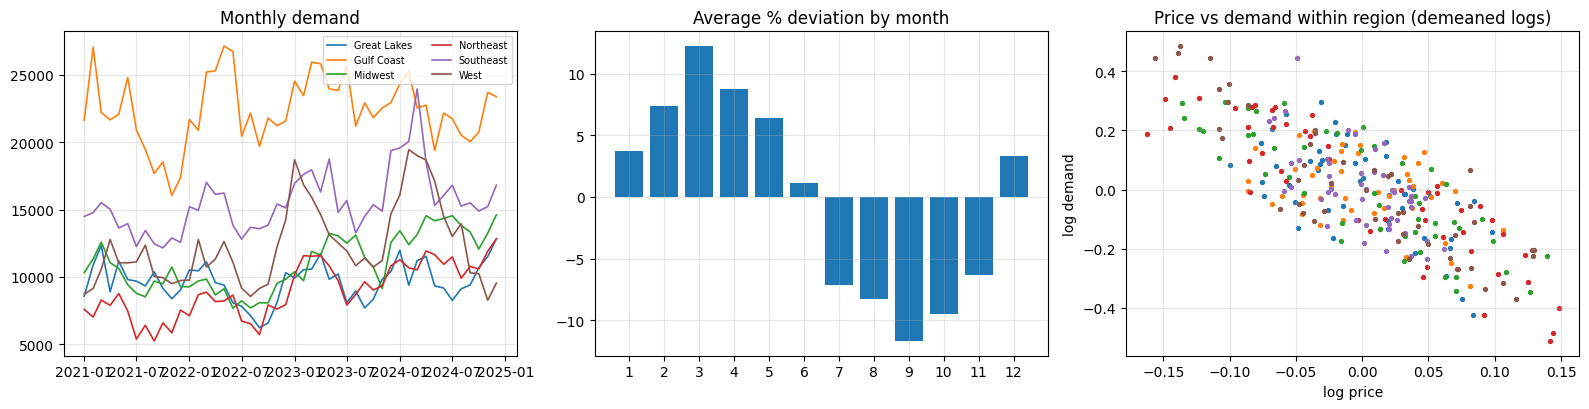

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for reg, g in df.groupby("region"):
    axes[0].plot(g["date"], g["demand_tons"], lw=1.2, label=reg)
    axes[2].scatter(g["ln_price"] - g["ln_price"].mean(), g["ln_demand"] - g["ln_demand"].mean(), s=8)
axes[0].set_title("Monthly demand"); axes[0].legend(fontsize=7, ncol=2)

seas = 100 * (df.groupby("month")["ln_demand"].mean() - df["ln_demand"].mean())
axes[1].bar(seas.index, seas.values); axes[1].set_xticks(range(1, 13)); axes[1].set_title("Average % deviation by month")

axes[2].set_title("Price vs demand within region (demeaned logs)")
axes[2].set_xlabel("log price"); axes[2].set_ylabel("log demand")
plt.tight_layout(); plt.show()

Three things stand out:
- Demand grows over the period.
- There is a fairly regular dip from July to October.
- Within each region, higher prices go with clearly lower volumes.

The within-region part matters. Across regions, the big ones (Gulf Coast, Southeast) also tend to be the cheaper ones. Pooling everything would therefore mix up "large market" with "low price", which is why region fixed effects come in below.

## 4. Forecasting demand

I compared four approaches:
- **Last month (naive)**
- **Same month last year (seasonal naive)**
- **A log-linear regression.** Log demand on own price, competitor price, promo and the industrial index, with a separate intercept for each region and each calendar month.
- **Gradient boosting** on the same inputs, to see whether a more flexible model is worth it.

**Validation.** I used a rolling origin over 2024. The model is trained up to Dec-23 and forecasts Jan to Mar. Then it is retrained to Mar-24 and forecasts Apr to Jun, and so on. That gives four 3-month forecasts covering every month of 2024, each made only from data available at the time.

I also had to decide what the model is allowed to know in advance:
- Our own price and promo plans are known ahead, so I use their actual values.
- Competitor price and the industrial index are not known ahead, so I hold them at their last observed value. Using the actuals would flatter the model.

**Metric: WAPE**, total absolute error divided by total actual volume. It puts regions of different size on one scale. It doesn't blow up on low months the way MAPE can. And it is easy to explain as "tons off per ton sold".

In [15]:
FORMULA = "ln_demand ~ ln_price + ln_comp_price + promo_flag + ln_index + C(region) + C(month)"
GB_FEATURES = ["ln_price", "ln_comp_price", "promo_flag", "ln_index", "month", "region_code"]

def fit_loglinear(data):
    m = smf.ols(FORMULA, data=data).fit()
    return m, np.mean(np.exp(m.resid))      # smearing factor when going back from logs to tons

def wape(actual, pred):
    return np.abs(actual - pred).sum() / actual.sum()

history = df.set_index(["region", "date"])["demand_tons"]
folds = []
for origin in ["2023-12-01", "2024-03-01", "2024-06-01", "2024-09-01"]:
    o = pd.Timestamp(origin)
    train = df[df["date"] <= o]
    test = df[(df["date"] > o) & (df["date"] <= o + pd.DateOffset(months=3))].copy()

    last = df[df["date"] == o].set_index("region")
    for col in ["ln_comp_price", "ln_index"]:        # not known in advance -> hold at last value
        test[col] = test["region"].map(last[col])

    test["naive"] = test["region"].map(last["demand_tons"])
    test["seasonal_naive"] = [history[(r, d - pd.DateOffset(years=1))] for r, d in zip(test["region"], test["date"])]

    m, smear = fit_loglinear(train)
    test["regression"] = np.exp(m.predict(test)) * smear

    gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)
    gb.fit(train[GB_FEATURES], train["ln_demand"])
    test["gradient_boosting"] = np.exp(gb.predict(test[GB_FEATURES]))
    test["origin"] = origin
    folds.append(test)

bt = pd.concat(folds, ignore_index=True)
models = ["naive", "seasonal_naive", "gradient_boosting", "regression"]

scores = pd.DataFrame({
    "WAPE %": [100 * wape(bt["demand_tons"], bt[m]) for m in models],
    "bias %": [100 * (bt[m].sum() / bt["demand_tons"].sum() - 1) for m in models],
}, index=models).round(1)
scores

,WAPE %,bias %
naive,10.5,0.5
seasonal_naive,12.9,-4.5
gradient_boosting,9.7,-4.2
regression,5.4,-1.4


In [16]:
pd.DataFrame({m: bt.groupby("region")[["demand_tons", m]].apply(lambda g, m=m: 100 * wape(g["demand_tons"], g[m]))
              for m in models}).round(1)

,naive,seasonal_naive,gradient_boosting,regression
region,,,,
Great Lakes,12.6,11.3,7.4,5.9
Gulf Coast,7.4,9.3,14.5,4.7
Midwest,5.9,14.8,6.5,3.9
Northeast,6.6,13.0,7.3,5.9
Southeast,15.3,12.2,8.0,6.4
West,15.5,18.9,10.8,5.8


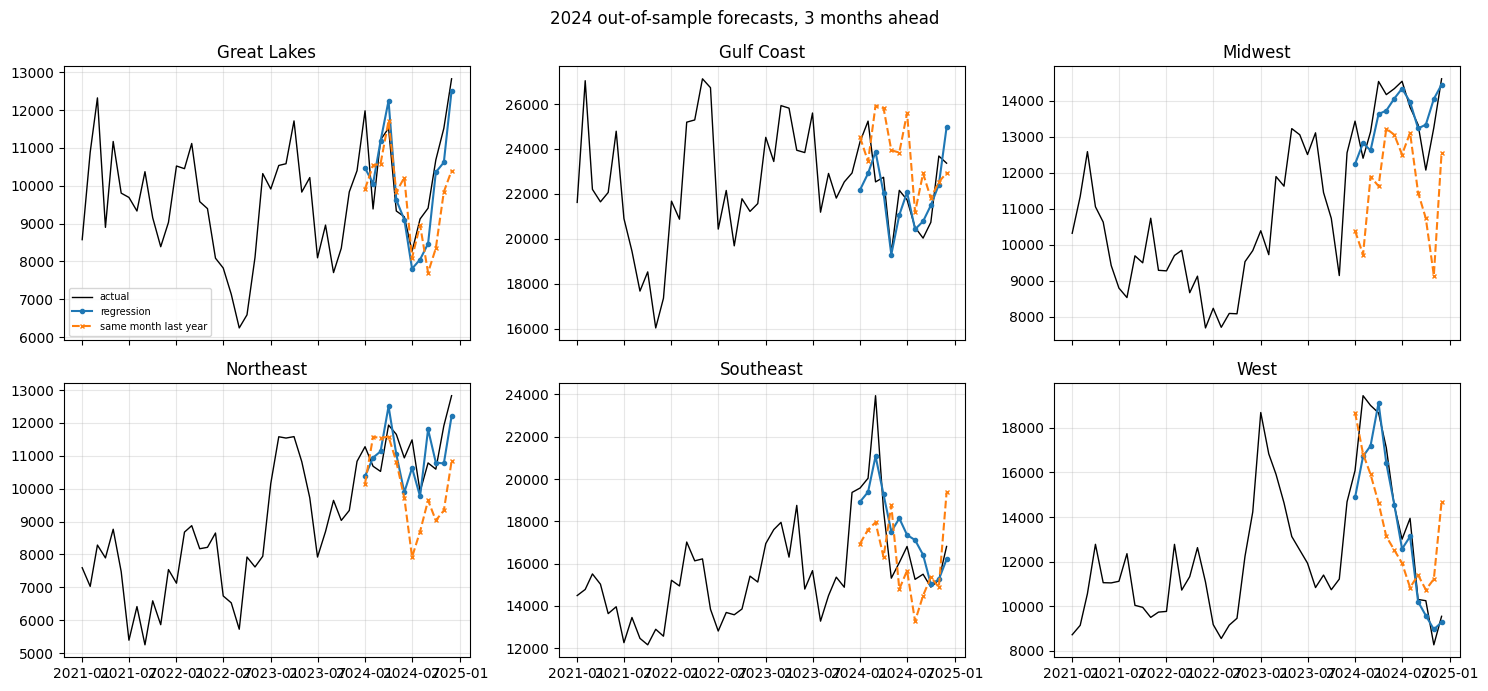

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, (reg, g) in zip(axes.ravel(), df.groupby("region")):
    b = bt[bt["region"] == reg]
    ax.plot(g["date"], g["demand_tons"], "k-", lw=1, label="actual")
    ax.plot(b["date"], b["regression"], "o-", ms=3, label="regression")
    ax.plot(b["date"], b["seasonal_naive"], "x--", ms=3, label="same month last year")
    ax.set_title(reg)
axes[0, 0].legend(fontsize=7)
fig.suptitle("2024 out-of-sample forecasts, 3 months ahead"); plt.tight_layout(); plt.show()

The regression comes in at about 5% WAPE, against roughly 10 to 13% for the two benchmarks. It is the best of the four in every region.

Gradient boosting improves on the benchmarks but not on the regression. With under 300 rows there isn't much for it to learn. Trees also can't extrapolate, and the industrial index reached levels in 2024 that weren't in the training data.

The regression has a practical advantage too: its price coefficient is the elasticity I need in the next step. So I'm using the simpler model.

**Q1-2025 forecast at current prices.** Here "current" means the Q4-2024 average price in each region. Competitor price and the index are held at their latest levels, and there is no promo.

In [18]:
model, smear = fit_loglinear(df)
q4 = df[df["date"] >= "2024-10-01"].groupby("region")
dec = df[df["date"] == "2024-12-01"].set_index("region")
regions = sorted(df["region"].unique())

q1 = pd.DataFrame([{
    "region": r, "month": m, "current_price": q4["price_usd_per_ton"].mean()[r],
    "ln_comp_price": np.log(q4["competitor_price_usd_per_ton"].mean()[r]),
    "ln_index": dec.loc[r, "ln_index"], "promo_flag": 0,
    "capacity": dec.loc[r, "monthly_capacity_tons"]} for r in regions for m in (1, 2, 3)])
q1["ln_price"] = np.log(q1["current_price"])
q1["forecast"] = np.exp(model.predict(q1)) * smear

fc = q1.pivot(index="region", columns="month", values="forecast").round(0)
fc.columns = ["Jan-25", "Feb-25", "Mar-25"]
fc["Q1 total"] = fc.sum(axis=1)
fc["Q1 capacity"] = q1.groupby("region")["capacity"].sum()
fc["demand / capacity"] = (fc["Q1 total"] / fc["Q1 capacity"]).map("{:.0%}".format)
fc

,Jan-25,Feb-25,Mar-25,Q1 total,Q1 capacity,demand / capacity
region,,,,,,
Great Lakes,11793.0,12148.0,12400.0,36341.0,33600.0,108%
Gulf Coast,25584.0,26354.0,26900.0,78838.0,75600.0,104%
Midwest,15432.0,15897.0,16226.0,47555.0,39900.0,119%
Northeast,13277.0,13676.0,13960.0,40913.0,34500.0,119%
Southeast,17109.0,17623.0,17989.0,52721.0,52800.0,100%
West,10915.0,11243.0,11476.0,33634.0,47700.0,71%


At current prices, forecast demand is above capacity in Great Lakes, Gulf Coast, Midwest and Northeast. Southeast is right at its limit. Only the West has real spare capacity. This ends up driving most of the pricing recommendation.

## 5. Price elasticity

The model is the same log-linear specification as above, and the coefficient on log price is the own-price elasticity.

To make sure the estimate isn't just reflecting the model setup, I fitted several versions:
1. A pooled regression with no controls, for comparison.
2. Region fixed effects plus controls.
3. Region and month fixed effects (the main model).
4. Region and year-month fixed effects, which absorb anything common to all regions in a given month.
5. The main model plus a separate time trend per region.
6. The main model on 2021-22 only.
7. The main model on 2023-24 only.

**Standard errors.** I cluster by region. Six clusters is few, so I also checked HC1 and Newey-West (panel) errors, and I use whichever is widest.

In [19]:
controls = "ln_comp_price + promo_flag + ln_index"
specs = {
    "pooled, no controls": "ln_demand ~ ln_price",
    "region FE": f"ln_demand ~ ln_price + {controls} + C(region)",
    "region + month FE (main)": FORMULA,
    "region + year-month FE": f"ln_demand ~ ln_price + {controls} + C(region) + C(ym)",
    "main + region trends": f"ln_demand ~ ln_price + {controls} + C(region) * t + C(month)",
}

def fit_se(formula, data):
    g = data["region_code"]
    fits = [smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": g}),
            smf.ols(formula, data).fit(cov_type="HC1"),
            smf.ols(formula, data).fit(cov_type="hac-panel", cov_kwds={"groups": g, "maxlags": 3})]
    return fits[0], max(f.bse["ln_price"] for f in fits)

rows = []
runs = [(k, f, df) for k, f in specs.items()] + [
    ("main, 2021-22 only", FORMULA, df[df["year"] <= 2022]),
    ("main, 2023-24 only", FORMULA, df[df["year"] >= 2023])]
for name, f, data in runs:
    fit, se = fit_se(f, data)
    rows.append({"model": name, "elasticity": fit.params["ln_price"], "se": se,
                 "competitor price": fit.params.get("ln_comp_price"), "promo": fit.params.get("promo_flag"),
                 "industrial index": fit.params.get("ln_index"), "R2": fit.rsquared})
elasticity_table = pd.DataFrame(rows).set_index("model").round(3)
elasticity_table

,elasticity,se,competitor price,promo,industrial index,R2
model,,,,,,
"pooled, no controls",-3.045,0.693,NaN,NaN,NaN,0.533
region FE,-1.996,0.170,0.460,0.088,1.656,0.936
region + month FE (main),-2.062,0.052,0.484,0.079,1.508,0.982
region + year-month FE,-2.019,0.056,0.491,0.077,0.762,0.985
main + region trends,-2.059,0.065,0.472,0.078,0.905,0.983
"main, 2021-22 only",-2.051,0.097,0.563,0.073,1.568,0.985
"main, 2023-24 only",-2.042,0.122,0.459,0.077,1.214,0.979


In [20]:
main, SE = fit_se(FORMULA, df)
E = main.params["ln_price"]
print(f"own-price elasticity  {E:.2f}  (95% CI {E - 1.96*SE:.2f} to {E + 1.96*SE:.2f})")
print(f"competitor price      {main.params['ln_comp_price']:+.2f}")
print(f"promo uplift          {100*(np.exp(main.params['promo_flag'])-1):+.1f}%")
print(f"industrial index      {main.params['ln_index']:+.2f}")

own-price elasticity  -2.06  (95% CI -2.16 to -1.96)
competitor price      +0.48
promo uplift          +8.2%
industrial index      +1.51


Once regions are compared with themselves, the estimate barely moves: between -2.00 and -2.06 in every version, and the same in both halves of the data.

The pooled number (-3.0) is the odd one out. It overstates sensitivity because it confuses region size with price level.

Next I checked whether the regions actually differ from each other, and ran some quick residual diagnostics.

             elasticity    se
Great Lakes       -2.09  0.14
Gulf Coast        -1.86  0.16
Midwest           -2.06  0.09
Northeast         -2.03  0.09
Southeast         -1.98  0.24
West              -2.16  0.10 

F-test, all regions equal: p = 0.74

VIF: {'ln_price': 1.07, 'ln_comp_price': 1.01, 'promo_flag': 1.01, 'ln_index': 1.07}
Durbin-Watson by region: {'Great Lakes': 1.61, 'Gulf Coast': 1.81, 'Midwest': 2.1, 'Northeast': 1.98, 'Southeast': 1.76, 'West': 1.86}


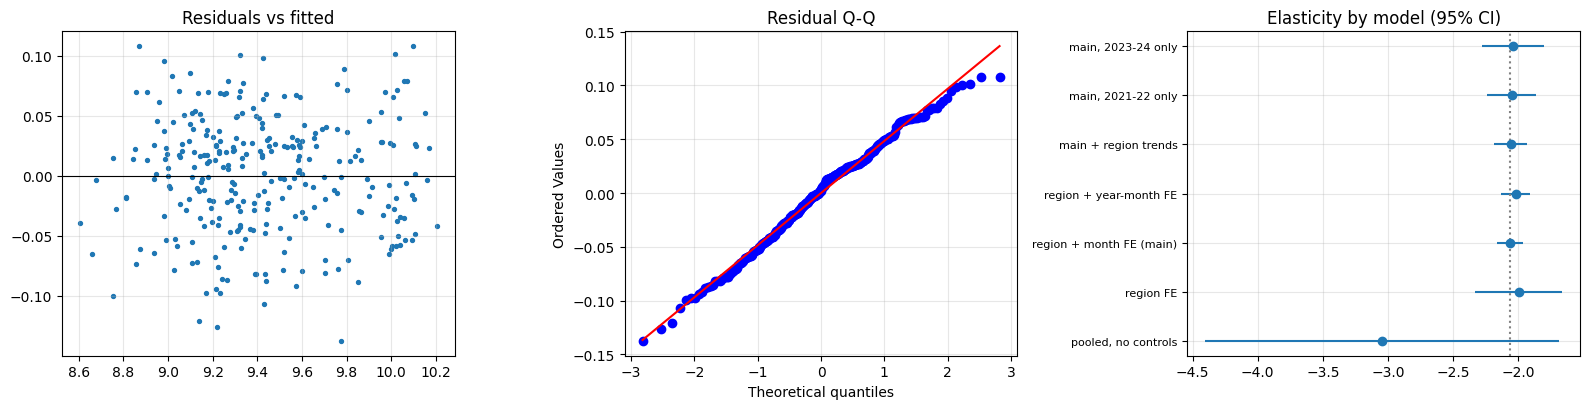

In [21]:
het = smf.ols(f"ln_demand ~ ln_price:C(region) + {controls} + C(region) + C(month)", df).fit(cov_type="HC1")
by_region = pd.DataFrame({"elasticity": het.params.filter(like="ln_price:"), "se": het.bse.filter(like="ln_price:")})
by_region.index = [i.split("[")[1].rstrip("]") for i in by_region.index]
terms = list(het.params.filter(like="ln_price:").index)
p_equal = float(het.f_test(", ".join(f"{terms[0]} = {t}" for t in terms[1:])).pvalue)
print(by_region.round(2), f"\n\nF-test, all regions equal: p = {p_equal:.2f}")

X = df[["ln_price", "ln_comp_price", "promo_flag", "ln_index"]].assign(const=1.0)
print("\nVIF:", {c: round(float(variance_inflation_factor(X.values, i)), 2) for i, c in enumerate(X.columns[:4])})
print("Durbin-Watson by region:", df.assign(r=main.resid).groupby("region")["r"].apply(lambda s: round(durbin_watson(s), 2)).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].scatter(main.fittedvalues, main.resid, s=8); axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("Residuals vs fitted")
st.probplot(main.resid, plot=axes[1]); axes[1].set_title("Residual Q-Q")
t = elasticity_table
axes[2].errorbar(t["elasticity"], range(len(t)), xerr=1.96 * t["se"], fmt="o")
axes[2].set_yticks(range(len(t))); axes[2].set_yticklabels(t.index, fontsize=8)
axes[2].axvline(E, color="grey", ls=":"); axes[2].set_title("Elasticity by model (95% CI)")
plt.tight_layout(); plt.show()

The regional estimates range from about -1.9 to -2.2, and the test can't tell them apart (p = 0.74). I therefore use a single elasticity for every region.

The diagnostics give no cause for concern:
- The residuals look well behaved.
- The VIFs are close to 1.
- The Durbin-Watson statistics are all near 2.

**What this means commercially.** A 1% price increase costs about 2.1% of volume. Revenue therefore falls when price goes up. Profit is a different question: every ton we don't sell also saves $600 of cost, so a price rise can still improve contribution margin.

**Caveat.** This is historical, not experimental, data. If prices were sometimes raised *because* demand was strong, the true elasticity would be somewhat more negative than this estimate. I allow for that in the pricing section by re-running it at -2.4.

## 6. Pricing for Q1-2025

The objective is quarterly contribution:

> (price - $600) x tons sold, where tons sold is the lower of forecast demand at that price and plant capacity.

Demand at a new price scales from the Q1 forecast with the elasticity: D(p) = D(p0) x (p / p0)^e.

Without a capacity limit, constant elasticity gives a simple answer: the best price is cost x e / (1 + e), about $1,165/t here. Where a plant is already sold out, raising the price costs nothing in volume until demand falls back to capacity, so the case for an increase is even stronger.

I don't want to push the model further than the data supports, so I set three limits:
- Stay within the range of prices each region has actually charged in 2021-24.
- Move by no more than 10% in a single quarter.
- Leave the price unchanged if the gain would be under 1%.

In [22]:
GRID = np.arange(700, 1501, 1.0)
price_range = df.groupby("region")["price_usd_per_ton"].agg(["min", "max"])
at = lambda p, arr: float(np.interp(p, GRID, arr))

def quarter(base, e):
    p0 = base["current_price"].iloc[0]
    demand = base["forecast"].to_numpy()[:, None] * (GRID / p0) ** e
    sold = np.minimum(demand, base["capacity"].to_numpy()[:, None])
    return ((GRID - VARIABLE_COST) * sold).sum(0), sold.sum(0)

def best_price(reg, base, e):
    p0 = base["current_price"].iloc[0]
    margin, _ = quarter(base, e)
    lo = max(price_range.loc[reg, "min"], 0.9 * p0)
    hi = min(price_range.loc[reg, "max"], 1.1 * p0)
    ok = (GRID >= lo) & (GRID <= hi)
    p = round(GRID[ok][margin[ok].argmax()] / 5) * 5
    return (p if at(p, margin) >= 1.01 * at(p0, margin) else round(p0 / 5) * 5), lo, hi

print(f"unconstrained optimum: ${VARIABLE_COST * E / (1 + E):,.0f}/t")

rows, curves = [], {}
for reg, base in q1.groupby("region"):
    p0 = base["current_price"].iloc[0]
    p, lo, hi = best_price(reg, base, E)
    margin, sold = quarter(base, E)
    curves[reg] = (margin, p0, p, lo, hi)
    cap = base["capacity"].sum()
    rows.append({"region": reg, "current $/t": p0, "recommended $/t": p, "change %": 100 * (p / p0 - 1),
                 "capacity used now %": 100 * at(p0, sold) / cap, "capacity used after %": 100 * at(p, sold) / cap,
                 "Q1 margin now $M": at(p0, margin) / 1e6, "Q1 margin after $M": at(p, margin) / 1e6,
                 "tons now": at(p0, sold), "tons after": at(p, sold)})
rec = pd.DataFrame(rows).set_index("region")
rec["gain $M"] = rec["Q1 margin after $M"] - rec["Q1 margin now $M"]
rec.drop(columns=["tons now", "tons after"]).round(1)

unconstrained optimum: $1,165/t


,current $/t,recommended $/t,change %,capacity used now %,capacity used after %,Q1 margin now $M,Q1 margin after $M,gain $M
region,,,,,,,,
Great Lakes,1101.9,1165,5.7,100.0,96.4,16.9,18.3,1.4
Gulf Coast,957.0,1050,9.7,100.0,86.1,27.0,29.3,2.3
Midwest,1002.7,1105,10.2,100.0,97.6,16.1,19.7,3.6
Northeast,926.6,1020,10.1,100.0,97.3,11.3,14.1,2.8
Southeast,968.3,1060,9.5,99.1,82.8,19.3,20.1,0.9
West,1090.7,1090,-0.1,70.5,70.6,16.5,16.5,-0.0


In [23]:
now, after = rec["Q1 margin now $M"].sum(), rec["Q1 margin after $M"].sum()
print(f"Q1 contribution: ${now:.1f}M -> ${after:.1f}M  (+${after - now:.1f}M, {100*(after/now - 1):+.1f}%)")
print(f"Q1 volume: {100*(rec['tons after'].sum() / rec['tons now'].sum() - 1):+.1f}%")

# same prices, different elasticity assumptions
for e in (-1.8, -2.4):
    n = a = 0
    for reg, base in q1.groupby("region"):
        m, _ = quarter(base, e)
        n += at(base["current_price"].iloc[0], m)
        a += at(rec.loc[reg, "recommended $/t"], m)
    print(f"if elasticity were {e}: gain {100*(a/n - 1):+.1f}%")

Q1 contribution: $107.0M -> $118.0M  (+$11.0M, +10.3%)
Q1 volume: -8.2%
if elasticity were -1.8: gain +12.2%
if elasticity were -2.4: gain +7.6%


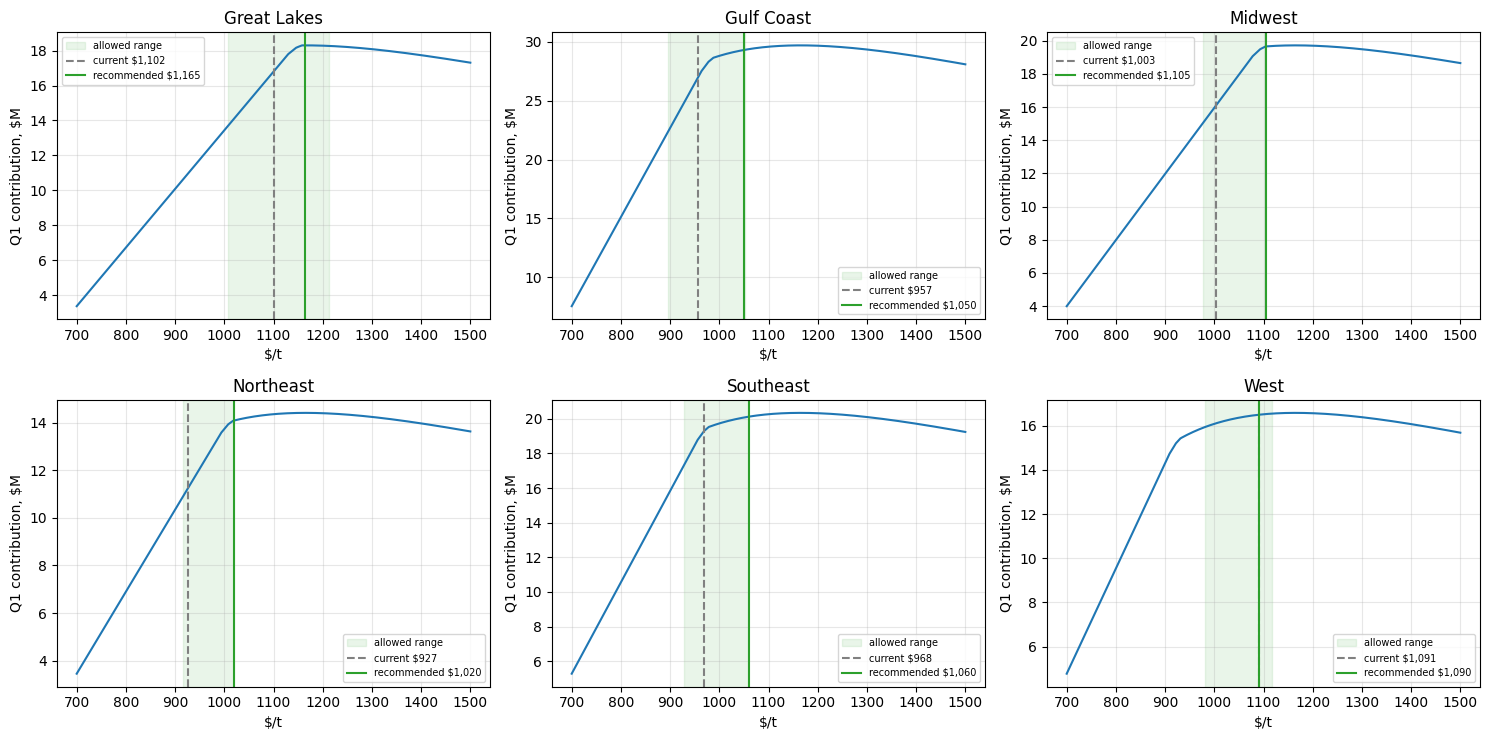

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, reg in zip(axes.ravel(), regions):
    margin, p0, p, lo, hi = curves[reg]
    ax.plot(GRID, margin / 1e6)
    ax.axvspan(lo, hi, color="tab:green", alpha=0.1, label="allowed range")
    ax.axvline(p0, color="grey", ls="--", label=f"current ${p0:,.0f}")
    ax.axvline(p, color="tab:green", label=f"recommended ${p:,.0f}")
    ax.set_title(reg); ax.set_xlabel("$/t"); ax.set_ylabel("Q1 contribution, $M"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

The result splits the regions into two groups.

**Five regions: raise prices by 6-10%.** These plants are sold out or close to it at today's prices. Most of the volume we'd lose is volume they couldn't have produced anyway, so the extra margin per ton comes through almost in full.

**West: hold.** It has around 30% spare capacity and is already priced near the top of its historical range, so an increase doesn't pay.

In four regions the limits stop the increase short of the ~$1,165 the model would pick. That's deliberate: I'd rather take a step, see how customers and competitors respond, and go again next quarter.

Across the portfolio this comes to roughly +$11M of contribution in Q1 (+10%), with about 8% less volume. If customers are more sensitive than estimated (-2.4), the gain drops to about 8%, but it stays positive in every region.

## 7. Summary for the commercial team

**Recommendation:** raise prices by 6-10% in five regions for Q1 and keep the West where it is. We expect this to add about $11M of contribution margin over the quarter (+10%). Sales volume falls by about 8%, mostly in regions that can't currently make everything customers want.

| Region | Q4-24 price ($/t) | Proposed Q1 price ($/t) | Change | Extra Q1 margin |
|---|---|---|---|---|
| Midwest | 1,003 | 1,105 | +10% | +$3.6M |
| Northeast | 927 | 1,020 | +10% | +$2.8M |
| Gulf Coast | 957 | 1,050 | +10% | +$2.3M |
| Great Lakes | 1,102 | 1,165 | +6% | +$1.4M |
| Southeast | 968 | 1,060 | +10% | +$0.9M |
| West | 1,091 | no change | - | - |

**Why**
- Customers do respond to price. A 1% increase loses about 2% of volume, and this is consistent across every region and over time. But at $350-500 margin per ton, the extra margin on the tons we keep is worth more than the tons we lose, up to roughly $1,165/t.
- At current prices, four plants have more demand than they can supply in Q1, and a fifth is at its limit. Pricing low in a sold-out region gives away margin without selling any more.
- The West is the exception. It has spare capacity and is already priced at the high end, so there's nothing to gain there.

**How reliable this is**
- The demand model was tested on 2024 as if that year hadn't happened yet. It was within about 5% overall, roughly twice as accurate as simple rules of thumb.
- If customers turn out to be more price-sensitive than we measured, the gain shrinks from about 10% to about 8%, but no region loses money.

**Risks**
- Every proposed price is one the region has charged before, and no change exceeds 10%, so we aren't moving into unknown territory.
- The data can't tell us how competitors will react. If they hold their prices, we lose some share (already included in the numbers above). If they follow us up, we lose less. A competitor cutting price in response would change the picture.
- Key accounts and contract terms should be checked before any change goes out.

**Suggested next steps**
1. Start with Midwest and Northeast, which have the largest gain and the tightest capacity.
2. Track volumes weekly against the forecast, and review any region running more than about 3% below.
3. If the business is open to it, a deliberate price test in one region would tell us much more about customer sensitivity than history alone.

## 8. Assumptions and what I'd do with more time

**Assumptions**
- The data corrections in section 2 are right. Each one is flagged in the cleaned file, so they can be undone.
- For Q1, competitor price stays at its Q4 average, the industrial index stays at its December level, and there is no promotion.
- Variable cost is a flat $600/t everywhere. Capacity is treated as a hard limit for planning, even though it was sometimes exceeded historically.
- After controlling for region, season, competitor price, promo and the industrial index, the remaining price variation is treated as unrelated to demand shocks.

**With more time I would:**
- Look for a cost-side variable that moves price but not demand, and use it as an instrument to firm up the elasticity. A proper regional price test would be better still.
- Forecast competitor price and the industrial index instead of holding them flat, and add prediction intervals to the demand forecast.
- Think about how competitors are likely to respond and run scenarios around that.
- Let the regional elasticities differ through a hierarchical model as more data comes in.
- Bring in contract and customer-mix information so capacity is handled more precisely.

In [25]:
df.to_csv(OUT_DIR / "panel_clean.csv", index=False)
cleaning_log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
scores.to_csv(OUT_DIR / "forecast_backtest.csv")
fc.to_csv(OUT_DIR / "forecast_q1_2025.csv")
elasticity_table.to_csv(OUT_DIR / "elasticity.csv")
rec.round(2).to_csv(OUT_DIR / "pricing_recommendation.csv")
sorted(p.name for p in OUT_DIR.iterdir())

['cleaning_log.csv',
 'elasticity.csv',
 'forecast_backtest.csv',
 'forecast_q1_2025.csv',
 'panel_clean.csv',
 'pricing_recommendation.csv']